# Лабораторна робота №1
## Підготовка та дослідницький аналіз даних для машинного навчання

**Мета:** провести підготовку та дослідницький аналіз даних з використанням Pandas, NumPy та Scikit-learn; виконати очищення даних, обробку пропусків, кодування категоріальних ознак, масштабування числових ознак і поділ на навчальну та тестову вибірки.

## 1. Вибір набору даних

Обрано датасет **Telco Customer Churn** - дані телеком-компанії про клієнтів: послуги, тип контракту, спосіб оплати, щомісячні та загальні платежі. Цільова змінна `Churn` (Yes/No) показує, чи пішов клієнт. Задача - бінарна класифікація.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Завантаження даних

In [40]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

rows, columns = df.shape
print("Кількість записів:", rows)
print("Кількість ознак:", columns)

Кількість записів: 7043
Кількість ознак: 21


In [41]:
print("Назви стовпців:")
print(list(df.columns))

Назви стовпців:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [42]:
types_table = pd.DataFrame({
    "Стовпець": df.columns,
    "Тип даних": df.dtypes.astype(str).values
})
types_table

,Стовпець,Тип даних
0,customerID,object
1,gender,object
2,SeniorCitizen,int64
3,Partner,object
4,Dependents,object
5,tenure,int64
6,PhoneService,object
7,MultipleLines,object
8,InternetService,object
9,OnlineSecurity,object


## 3. Дослідницький аналіз даних (EDA)

### Перші та останні записи

In [43]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [44]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### Статистичні характеристики числових ознак

In [45]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


`TotalCharges` немає в `describe()`, хоча це сума грошей. Значить pandas зчитав цей стовпець як текст - перевіримо це нижче.

### Розподіл значень категоріальних ознак

In [46]:
text_columns = df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"])

for column in text_columns:
    print(column)
    print(df[column].value_counts())
    print()

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
TechSupport
No              

In [47]:
print("SeniorCitizen")
print(df["SeniorCitizen"].value_counts())

SeniorCitizen
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


### Кількість унікальних значень

In [48]:
unique_table = pd.DataFrame({
    "Стовпець": df.columns,
    "Унікальних значень": df.nunique().values
})
unique_table

,Стовпець,Унікальних значень
0,customerID,7043
1,gender,2
2,SeniorCitizen,2
3,Partner,2
4,Dependents,2
5,tenure,73
6,PhoneService,2
7,MultipleLines,3
8,InternetService,3
9,OnlineSecurity,3


### Пропущені значення, дублікати, некоректні значення

In [49]:
missing_table = pd.DataFrame({
    "Пропусків": df.isnull().sum(),
    "Відсоток": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_table

,Пропусків,Відсоток
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [50]:
print("Кількість дублікатів:", df.duplicated().sum())
print("Кількість дублікатів без customerID:", df.drop(columns=["customerID"]).duplicated().sum())
print("Кількість повторів customerID:", df["customerID"].duplicated().sum())

Кількість дублікатів: 0
Кількість дублікатів без customerID: 22
Кількість повторів customerID: 0


In [51]:
empty_total = df["TotalCharges"].str.strip() == ""
print("Рядків з пробілом замість TotalCharges:", empty_total.sum())
df.loc[empty_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Рядків з пробілом замість TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [52]:
print("Рядків з tenure == 0:", (df["tenure"] == 0).sum())
print("Від'ємних значень tenure:", (df["tenure"] < 0).sum())
print("Від'ємних значень MonthlyCharges:", (df["MonthlyCharges"] < 0).sum())
print("Нульових значень MonthlyCharges:", (df["MonthlyCharges"] == 0).sum())

Рядків з tenure == 0: 11
Від'ємних значень tenure: 0
Від'ємних значень MonthlyCharges: 0
Нульових значень MonthlyCharges: 0


Формально пропусків у даних немає, але в `TotalCharges` є рядки з пробілом замість числа. Усі вони мають `tenure == 0`, тобто це нові клієнти, які ще не отримали жодного рахунку. Це приховані пропуски. Від'ємних значень у грошах і `tenure` немає.

### Викиди (попередньо, на всьому наборі)

In [53]:
total_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")
numeric_df = df[["tenure", "MonthlyCharges"]].copy()
numeric_df["TotalCharges"] = total_charges

for column in numeric_df.columns:
    q1 = numeric_df[column].quantile(0.25)
    q3 = numeric_df[column].quantile(0.75)
    iqr = q3 - q1
    outliers = ((numeric_df[column] < q1 - 1.5 * iqr) | (numeric_df[column] > q3 + 1.5 * iqr)).sum()
    print(column, "- викидів за IQR:", outliers)

tenure - викидів за IQR: 0
MonthlyCharges - викидів за IQR: 0
TotalCharges - викидів за IQR: 0


Це лише попередній погляд для EDA. Самі межі для обробки викидів будемо рахувати тільки на навчальній вибірці.

### Графіки розподілів

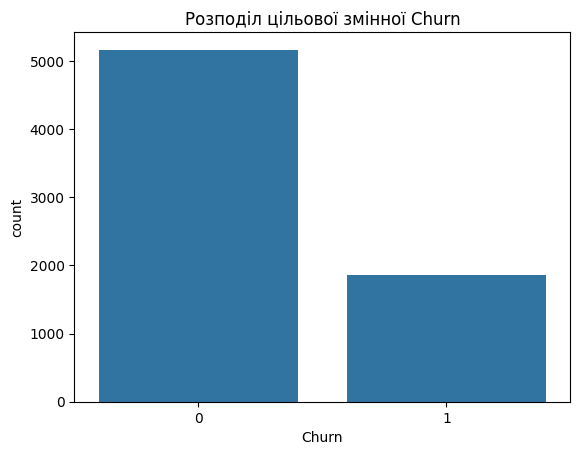

Частка класів:
Churn
0    0.736
1    0.264
Name: proportion, dtype: float64


In [77]:
sns.countplot(x="Churn", data=df)
plt.title("Розподіл цільової змінної Churn")
plt.show()

print("Частка класів:")
print(df["Churn"].value_counts(normalize=True).round(3))

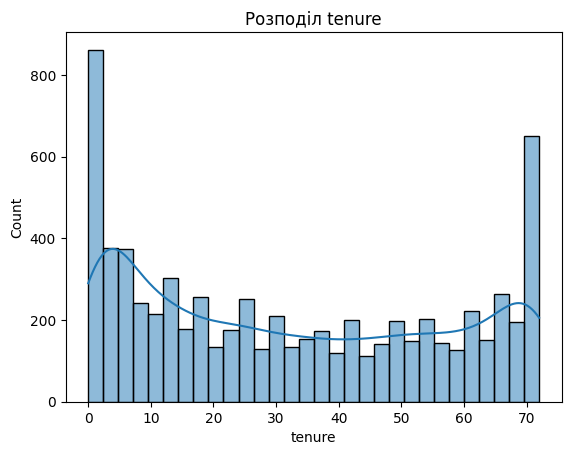

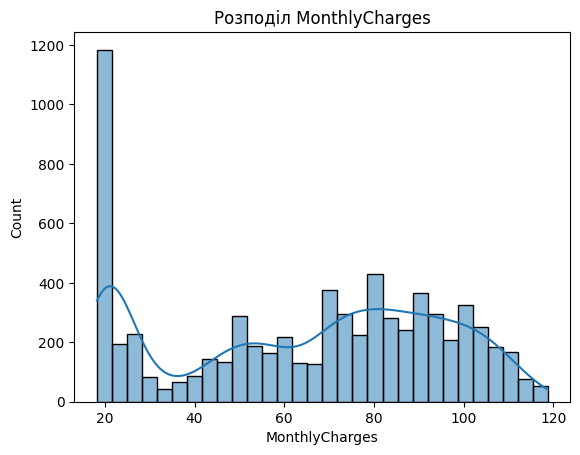

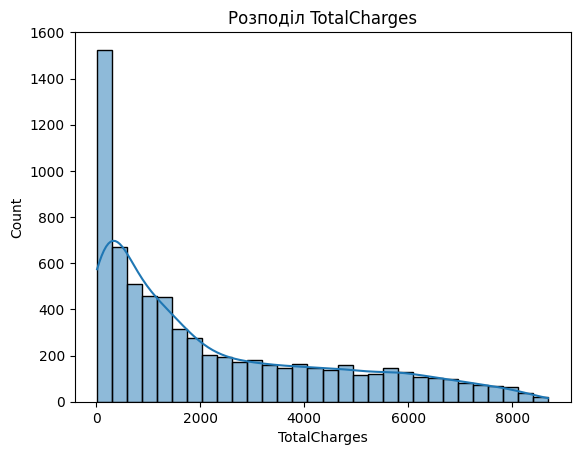

In [78]:
for column in numeric_df.columns:
    sns.histplot(numeric_df[column], bins=30, kde=True)
    plt.title("Розподіл " + column)
    plt.show()

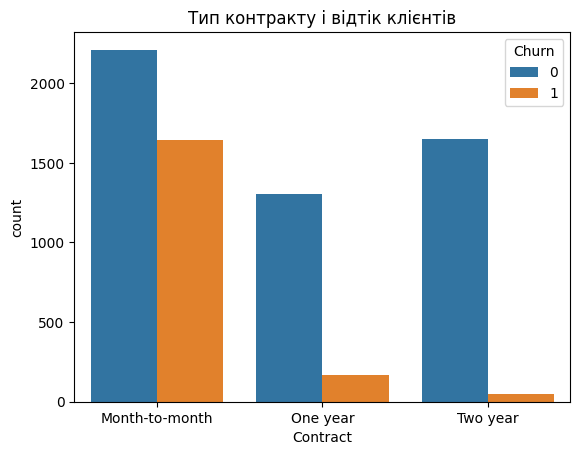

In [79]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Тип контракту і відтік клієнтів")
plt.show()

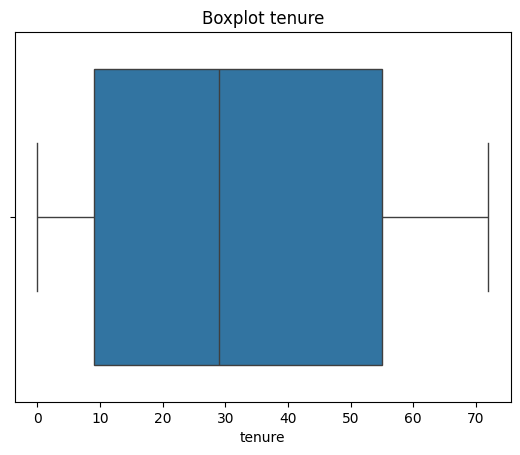

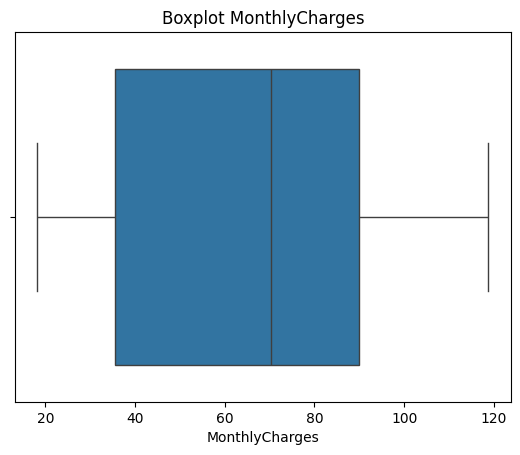

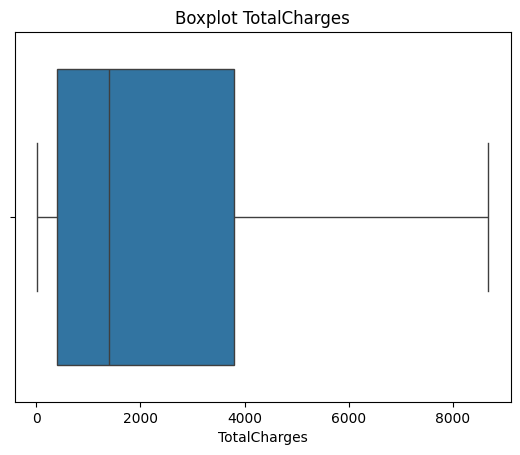

In [80]:
for column in numeric_df.columns:
    sns.boxplot(x=numeric_df[column])
    plt.title("Boxplot " + column)
    plt.show()

Класи незбалансовані: клієнтів, які пішли, приблизно чверть. `tenure` має два піки (нові клієнти і ті, що з компанією майже 6 років), `TotalCharges` сильно скошений вправо. Найбільше відтоку серед клієнтів з помісячним контрактом.

## 4. Очищення даних

In [58]:
print("Кількість записів до очищення:", len(df))

df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Тип TotalCharges після перетворення:", df["TotalCharges"].dtype)
print("Пропусків у TotalCharges:", df["TotalCharges"].isnull().sum())

Кількість записів до очищення: 7043
Тип TotalCharges після перетворення: float64
Пропусків у TotalCharges: 11


In [59]:
print("Дублікатів після видалення customerID:", df.duplicated().sum())
df = df.drop_duplicates()
print("Кількість записів після видалення дублікатів:", len(df))

Дублікатів після видалення customerID: 22
Кількість записів після видалення дублікатів: 7021


In [60]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print(df["Churn"].value_counts())

Churn
0    5164
1    1857
Name: count, dtype: int64


**Обґрунтування:**
- `customerID` - це просто унікальний номер клієнта, він не несе інформації для моделі, тому його видалено.
- `TotalCharges` перетворено в число через `pd.to_numeric(errors="coerce")`. Пробіли стали `NaN`. Ці пропуски заповнюємо вже після поділу на train/test, щоб не було витоку даних.
- Після видалення `customerID` знайшлися повністю однакові рядки. Вони не дають моделі нової інформації і можуть потрапити одночасно в train і test, тому видаляємо їх.
- `Churn` переведено в 1/0, бо модель працює з числами.
- `SeniorCitizen` вже має значення 0/1, тобто це вже закодована бінарна ознака. Її залишаємо як є, без кодування і масштабування.
- Значення `No internet service` і `No phone service` не є помилкою - це окрема категорія (клієнт не користується послугою), тому залишаємо їх.

## 5. Формування X та y

In [61]:
y = df["Churn"]
X = df.drop(columns=["Churn"])

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Розмір X: (7021, 19)
Розмір y: (7021,)


## 6. Поділ на навчальну та тестову вибірки

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5616, 19)
X_test: (1405, 19)
y_train: (5616,)
y_test: (1405,)


In [63]:
class_table = pd.DataFrame({
    "Весь набір": y.value_counts(normalize=True).round(3),
    "Train": y_train.value_counts(normalize=True).round(3),
    "Test": y_test.value_counts(normalize=True).round(3)
})
class_table

,Весь набір,Train,Test
Churn,,,
0,0.736,0.736,0.735
1,0.264,0.264,0.265


**Обґрунтування:** взято співвідношення 80/20. Записів близько 7 тисяч, тому 20% (приблизно 1400 рядків) достатньо для чесної перевірки, а на навчання лишається більшість даних. Оскільки класи незбалансовані, використано `stratify=y` - частка класів у train і test однакова, що видно в таблиці.

## 7. Обробка пропущених значень

In [64]:
X_train = X_train.copy()
X_test = X_test.copy()

missing_split = pd.DataFrame({
    "Пропусків X_train": X_train.isnull().sum(),
    "Пропусків X_test": X_test.isnull().sum()
})
missing_split[(missing_split["Пропусків X_train"] > 0) | (missing_split["Пропусків X_test"] > 0)]

,Пропусків X_train,Пропусків X_test
TotalCharges,9,2


In [65]:
X_train.loc[X_train["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
6754,0,61.90,NaN
1340,0,56.05,NaN
1082,0,25.75,NaN
4380,0,20.00,NaN
6670,0,73.35,NaN
488,0,52.55,NaN
5218,0,19.70,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN


In [66]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[["TotalCharges"]])

print("Медіана TotalCharges з X_train:", imputer.statistics_[0])

X_train[["TotalCharges"]] = imputer.transform(X_train[["TotalCharges"]])
X_test[["TotalCharges"]] = imputer.transform(X_test[["TotalCharges"]])

print("Пропусків у X_train:", X_train.isnull().sum().sum())
print("Пропусків у X_test:", X_test.isnull().sum().sum())

Медіана TotalCharges з X_train: 1396.0
Пропусків у X_train: 0
Пропусків у X_test: 0


**Обґрунтування:** пропуски є тільки в `TotalCharges`, їх дуже мало, і всі вони в нових клієнтів з `tenure == 0`. Тобто пропуск не випадковий, просто сума ще не нарахована. Видаляти ці рядки не хотілося, тому заповнили медіаною. Медіану взято замість середнього, бо розподіл `TotalCharges` сильно скошений. Медіана порахована тільки по `X_train` і та сама застосована до `X_test`. Логічно також можна було б поставити 0, але через малу кількість таких рядків на результат це майже не впливає.

## 8. Виявлення та аналіз викидів

In [67]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

lower_bounds = []
upper_bounds = []
train_outliers = []
test_outliers = []

for column in numeric_columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    lower_bounds.append(lower)
    upper_bounds.append(upper)
    train_outliers.append(((X_train[column] < lower) | (X_train[column] > upper)).sum())
    test_outliers.append(((X_test[column] < lower) | (X_test[column] > upper)).sum())

outliers_table = pd.DataFrame({
    "Ознака": numeric_columns,
    "Нижня межа": lower_bounds,
    "Верхня межа": upper_bounds,
    "Мінімум X_train": X_train[numeric_columns].min().values,
    "Максимум X_train": X_train[numeric_columns].max().values,
    "Викиди X_train": train_outliers,
    "Викиди X_test": test_outliers
})
outliers_table

,Ознака,Нижня межа,Верхня межа,Мінімум X_train,Максимум X_train,Викиди X_train,Викиди X_test
0,tenure,-61.5000,126.5000,0.00,72.00,0,0
1,MonthlyCharges,-45.0875,170.8125,18.25,118.75,0,0
2,TotalCharges,-4682.4875,8901.5125,18.85,8684.80,0,0


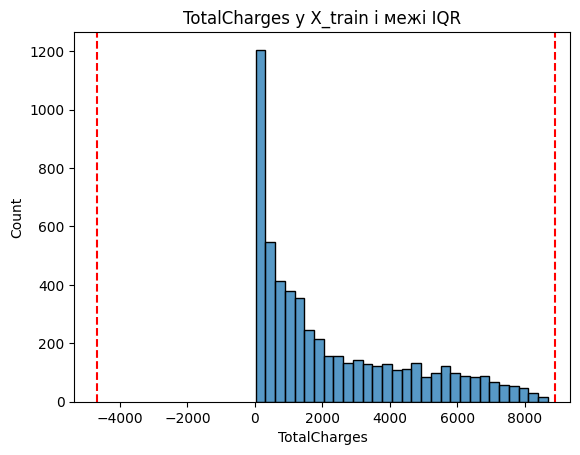

In [68]:
sns.histplot(X_train["TotalCharges"], bins=30)
plt.axvline(lower_bounds[2], color="red", linestyle="--")
plt.axvline(upper_bounds[2], color="red", linestyle="--")
plt.title("TotalCharges у X_train і межі IQR")
plt.show()

**Аналіз:** межі IQR пораховані тільки по `X_train`, до `X_test` застосовані ті самі межі без перерахунку. За правилом 1.5*IQR викидів у числових ознаках не знайдено. Великі значення `TotalCharges` - це не помилки, а клієнти, які довго користуються послугами і платять багато. Тому нічого не видаляємо і не обрізаємо.

## 9. Кодування категоріальних ознак

In [69]:
categorical_columns = list(X_train.select_dtypes(include="object").columns)
print("Категоріальних ознак:", len(categorical_columns))
print(categorical_columns)

Категоріальних ознак: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [70]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_columns])

encoded_columns = encoder.get_feature_names_out(categorical_columns)

X_train_encoded = pd.DataFrame(
    encoder.transform(X_train[categorical_columns]),
    columns=encoded_columns,
    index=X_train.index
)
X_test_encoded = pd.DataFrame(
    encoder.transform(X_test[categorical_columns]),
    columns=encoded_columns,
    index=X_test.index
)

print("Ознак після кодування у X_train:", X_train_encoded.shape[1])
print("Ознак після кодування у X_test:", X_test_encoded.shape[1])
print("Структура однакова:", list(X_train_encoded.columns) == list(X_test_encoded.columns))

Ознак після кодування у X_train: 41
Ознак після кодування у X_test: 41
Структура однакова: True


In [71]:
X_train_encoded.head()

,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2629,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2650,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1418,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5774,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2425,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


**Обґрунтування:** усі категоріальні ознаки номінальні, тобто в їхніх значеннях немає природного порядку (стать, спосіб оплати, тип інтернету і т.д.). Для таких ознак підходить One-Hot кодування, бо Ordinal штучно задав би порядок, якого немає. `handle_unknown="ignore"` потрібен на випадок, якщо в тесті трапиться категорія, якої не було в train. Енкодер навчено тільки на `X_train`.

## 10. Масштабування числових ознак

In [72]:
before_table = X_train[numeric_columns].describe().loc[["mean", "std", "min", "max"]].round(2)
before_table

,tenure,MonthlyCharges,TotalCharges
mean,32.43,64.89,2292.56
std,24.52,30.06,2274.06
min,0.00,18.25,18.85
max,72.00,118.75,8684.80


In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[numeric_columns])

X_train_scaled = pd.DataFrame(
    scaler.transform(X_train[numeric_columns]),
    columns=numeric_columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test[numeric_columns]),
    columns=numeric_columns,
    index=X_test.index
)

after_table = X_train_scaled.describe().loc[["mean", "std", "min", "max"]].round(2)
after_table

,tenure,MonthlyCharges,TotalCharges
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.32,-1.55,-1.00
max,1.61,1.79,2.81


In [74]:
X_test_scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges,TotalCharges
mean,0.01,-0.01,-0.01
std,1.00,1.00,0.98
min,-1.32,-1.54,-1.00
max,1.61,1.77,2.75


**Обґрунтування:** масштабуємо тільки `tenure`, `MonthlyCharges` і `TotalCharges`, бо вони мають дуже різні діапазони (десятки проти тисяч). One-Hot колонки і `SeniorCitizen` вже мають значення 0/1, їх не чіпаємо. Обрано стандартизацію (`StandardScaler`), бо в даних немає викидів, а багато моделей краще працюють з ознаками із середнім 0 і стандартним відхиленням 1. Після масштабування в train середнє 0 і std 1. У test значення близькі до 0 і 1, але не точно, бо використано параметри з train - так і має бути.

## 11. Підготовка остаточних даних

In [75]:
X_train_final = pd.concat([X_train_scaled, X_train[["SeniorCitizen"]], X_train_encoded], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test[["SeniorCitizen"]], X_test_encoded], axis=1)

print("Пропусків у X_train_final:", X_train_final.isnull().sum().sum())
print("Пропусків у X_test_final:", X_test_final.isnull().sum().sum())
print()
print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print()
print("Однакові колонки в train і test:", list(X_train_final.columns) == list(X_test_final.columns))
print("Усі ознаки числові:", X_train_final.select_dtypes(exclude="number").shape[1] == 0)

Пропусків у X_train_final: 0
Пропусків у X_test_final: 0

X_train_final: (5616, 45)
X_test_final: (1405, 45)
y_train: (5616,)
y_test: (1405,)

Однакові колонки в train і test: True
Усі ознаки числові: True


In [76]:
X_train_final.head()

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2629,-1.241331,0.193165,-0.946349,0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2650,-0.711078,0.647355,-0.435345,0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1418,1.409933,0.820380,1.794547,0,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5774,-1.118965,0.023467,-0.858745,0,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2425,-0.262403,-1.483847,-0.783388,0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


Тестова вибірка не використовувалася для підбору параметрів: `SimpleImputer`, межі IQR, `OneHotEncoder` і `StandardScaler` навчені (`fit`) тільки на `X_train`, а до `X_test` застосовано лише `transform`.

## 12. Висновки

**Якість початкових даних.** Датасет містив 7043 записи і 21 ознаку. Явних пропусків (`NaN`) не було, але в `TotalCharges` було 11 рядків з пробілом замість числа, через що весь стовпець зчитався як текст. Усі 11 рядків - нові клієнти з `tenure == 0`. Повних дублікатів не було, але після видалення `customerID` знайшлося 22 однакових рядки. Від'ємних чи явно неможливих значень у числових ознаках немає. Класи незбалансовані: 73.5% клієнтів залишились і 26.5% пішли.

**Виконані перетворення:**
- видалено `customerID`, `TotalCharges` перетворено в число, видалено 22 дублікати - залишилось 7021 запис, `Churn` закодовано як 1/0;
- дані поділено 80/20 зі `stratify=y`: 5616 записів у train і 1405 у test, частка класу 1 в обох приблизно 26.4-26.5%;
- пропуски в `TotalCharges` (9 у train, 2 у test) заповнено медіаною з train - 1396.0;
- викиди перевірено методом IQR з межами по train: у `tenure`, `MonthlyCharges` і `TotalCharges` викидів немає ні в train, ні в test, тому нічого не видаляли;
- 15 категоріальних ознак закодовано через One-Hot, після кодування вийшло 41 бінарна ознака;
- 3 числові ознаки стандартизовано `StandardScaler`, після цього в train середнє 0 і std 1, у test значення близькі (std від 0.98 до 1.00).

**Готовність до моделі.** Фінальні розмірності: `X_train_final` - (5616, 45), `X_test_final` - (1405, 45), `y_train` - (5616,), `y_test` - (1405,). 45 ознак = 3 масштабовані числові + `SeniorCitizen` + 41 One-Hot колонка. Пропусків немає, усі ознаки числові, структура колонок у train і test однакова. Усі параметри обробки (медіана, межі IQR, категорії енкодера, середнє і std скейлера) визначено тільки за навчальною вибіркою, тому витоку даних немає. Набір готовий до побудови моделі класифікації.